In [ ]:
'''Build a k-nearest neighbors (KNN) model with optimized distance metrics and 
scaling techniques to accurately classify applicants based on similar profiles
and past admission data.'''

In [2]:
import pandas as pd
import numpy as np

data = pd.read_csv("Adm.csv")

display(data.head())
print("dataset shape:", data.shape)

# check column types and missing values
print("\ncolumn information:")
data.info()

# count missing values in each column
print("\nmissing values:")
print(data.isnull().sum())

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


dataset shape: (1000, 12)

column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB

missing values:
Serial No.              0
GRE Score               0
T

In [4]:
#Prepare the data for classification
# create admission categories using a probability threshold of 0.75
data = data.dropna(subset=["Chance of Admit"]).copy()

data["Admission_Status"] = np.where(
    data["Chance of Admit"] >= 0.75,
    "Likely",
    "Less Likely"
)

# remove identifier, original target and unnecessary date columns
X = data.drop(
    columns=[
        "Serial No.",
        "Chance of Admit",
        "Admission_Status",
        "Application_DateTime"
    ],
    errors="ignore"
)

# store the admission category as the target
y = data["Admission_Status"]

# display the number of applicants in each category
print("admission category distribution:")
print(y.value_counts())

# display the feature columns
print("\nfeatures used:")
print(X.columns.tolist())

admission category distribution:
Admission_Status
Less Likely    565
Likely         435
Name: count, dtype: int64

features used:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'University_Name', 'region']


In [5]:
# identify numerical columns
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# identify categorical columns 
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# display the identified columns
print("numerical columns:", numerical_cols)
print("categorical columns:", categorical_cols)

numerical columns: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
categorical columns: ['University_Name', 'region']


In [6]:
#Build the preprocessing pipeline
# import libraries for missing value handling, scaling and encoding
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# fill missing numerical values with the median and scale them
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# fill missing text values and convert categories into numeric columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# apply the correct preprocessing to each type of column
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("preprocessing pipeline created successfully")

preprocessing pipeline created successfully


In [7]:
#split the dataset into training and testing data
# import library for splitting the dataset
from sklearn.model_selection import train_test_split

# split the data while keeping class proportions similar
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# display the number of records in each group
print("training records:", X_train.shape[0])
print("testing records:", X_test.shape[0])

training records: 800
testing records: 200


In [8]:
#Optimize KNN parameters and distance metrics
# import libraries for knn modeling and cross-validation
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# create the full pipeline so preprocessing is learned only from training folds
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier())
])

# define the combinations that the model will test
parameter_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__metric": ["euclidean", "manhattan", "minkowski"],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

# use stratified cross-validation to keep class proportions similar
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# search for the best parameter combination
knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=cross_validation,
    n_jobs=-1,
    verbose=1
)

# train and compare the different knn configurations
knn_search.fit(X_train, y_train)

# display the best settings selected by cross-validation
print("\nbest parameters:")
print(knn_search.best_params_)

print("\nbest cross-validation macro f1-score:")
print(round(knn_search.best_score_, 4))

Fitting 5 folds for each of 72 candidates, totalling 360 fits

best parameters:
{'model__metric': 'manhattan', 'model__n_neighbors': 11, 'model__p': 1, 'model__weights': 'distance'}

best cross-validation macro f1-score:
0.6694


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [0.6402626  0.63485037 0.6402626  0.63485037 0.64366735 0.64395238
 0.64366735 0.64395238 0.656488   0.65792865 0.656488   0.65792865
 0.64539401 0.64533665 0.64539401 0.64533665 0.64718593 0.64715428
 0.64718593 0.64715428 0.64864219 0.64651871 0.64864219 0.64651871
        nan 0.64412148        nan 0.64412148        nan 0.65914112
        nan 0.65914112        nan 0.65541742        nan 0.65541742
        nan 0.6674538         nan 0.6674538         nan 0.66941569
        nan 0.66941569        nan 0.66342509        nan 0.66342509
        nan 0.64412148 0.6402626  0.63485037        nan 0.65914112
 0.64366735 0.64395238        nan 0.65541742 0.656488   0.65792865
        nan 0.6674538  0.64539401 0.64533665        nan 0.66941569
 0.64718593 0.64715428        nan 0.66342509 0.64864219 0.64651871]
  warnings.warn(


In [9]:
#Select the best model
# select the best model found during parameter tuning
best_knn = knn_search.best_estimator_

# display the selected knn model
print("best knn model:")
print(best_knn)

# display the selected distance metric
print("\nbest distance metric:")
print(knn_search.best_params_["model__metric"])

# display the selected number of neighbors
print("\nbest number of neighbors:")
print(knn_search.best_params_["model__n_neighbors"])

best knn model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['GRE Score', 'TOEFL Score',
                                                   'University Rating', 'SOP',
                                                   'LOR', 'CGPA', 'Research']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  (

In [11]:
#Evaluate the optimized model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# predict admission categories for the test applicants
y_pred = best_knn.predict(X_test)

# calculate the model's performance scores
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

# display the evaluation results
print("knn model evaluation")
print("--------------------")
print(f"accuracy:  {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall:    {recall:.4f}")
print(f"macro f1:  {f1:.4f}")

# show precision, recall and f1-score for each class
print("\ndetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

knn model evaluation
--------------------
accuracy:  0.6400
precision: 0.6336
recall:    0.6193
macro f1:  0.6180

detailed classification report:
              precision    recall  f1-score   support

 Less Likely       0.65      0.78      0.71       113
      Likely       0.62      0.46      0.53        87

    accuracy                           0.64       200
   macro avg       0.63      0.62      0.62       200
weighted avg       0.64      0.64      0.63       200



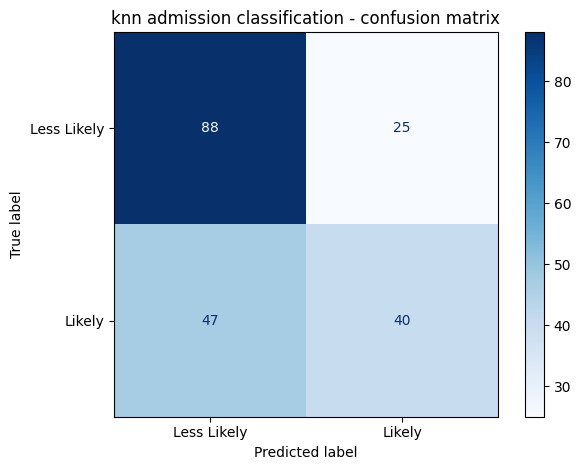

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# compare actual categories with the model predictions
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Less Likely", "Likely"],
    cmap="Blues",
    values_format="d"
)

# add a clear title to the chart
plt.title("knn admission classification - confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

# prepare a list to store the comparison results
distance_results = []

# compare euclidean, manhattan and minkowski distances
for metric in ["euclidean", "manhattan", "minkowski"]:

    # create a copy of the pipeline with the selected distance metric
    test_model = clone(knn_pipeline).set_params(
        model__metric=metric,
        model__n_neighbors=knn_search.best_params_["model__n_neighbors"],
        model__weights=knn_search.best_params_["model__weights"],
        model__p=knn_search.best_params_["model__p"]
    )

    # calculate cross-validation f1-score for this metric
    scores = cross_val_score(
        test_model,
        X_train,
        y_train,
        cv=cross_validation,
        scoring="f1_macro",
        n_jobs=-1
    )

    # store the average score for comparison
    distance_results.append({
        "Distance Metric": metric,
        "Mean F1 Score": scores.mean()
    })

# display the comparison table
distance_table = pd.DataFrame(distance_results)
display(distance_table.sort_values("Mean F1 Score", ascending=False))

,Distance Metric,Mean F1 Score
1,manhattan,0.669416
2,minkowski,0.669416
0,euclidean,0.647154


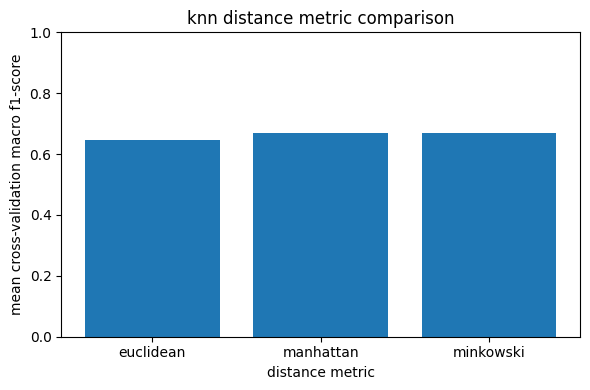

In [18]:
# plot the average f1-score for each distance metric
plt.figure(figsize=(6,4))

plt.bar(
    distance_table["Distance Metric"],
    distance_table["Mean F1 Score"]
)

# add chart labels
plt.title("knn distance metric comparison")
plt.xlabel("distance metric")
plt.ylabel("mean cross-validation macro f1-score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
# Predict the admission category for a new applicant
# take one existing applicant as a template
new_applicant = X.iloc[[0]].copy()

# replace example values only when the columns exist
example_values = {
    "GRE Score": 320,
    "TOEFL Score": 110,
    "University Rating": 4,
    "SOP": 4.0,
    "LOR": 4.0,
    "CGPA": 9.0,
    "Research": 1
}

for column, value in example_values.items():
    if column in new_applicant.columns:
        new_applicant.loc[:, column] = value

# predict the admission category using the trained model
predicted_status = best_knn.predict(new_applicant)[0]

# display the prediction
print("predicted admission category:", predicted_status)

# show the estimated probability for each category
probabilities = best_knn.predict_proba(new_applicant)[0]

for category, probability in zip(best_knn.classes_, probabilities):
    print(f"{category}: {probability:.2%}")

predicted admission category: Likely
Less Likely: 14.46%
Likely: 85.54%


In [19]:

# summarize the selected settings and test performance
summary = pd.DataFrame({
    "Evaluation": [
        "Best number of neighbors",
        "Best distance metric",
        "Best voting weights",
        "Cross-validation macro F1",
        "Test accuracy",
        "Test precision (macro)",
        "Test recall (macro)",
        "Test F1-score (macro)"
    ],
    "Result": [
        knn_search.best_params_["model__n_neighbors"],
        knn_search.best_params_["model__metric"],
        knn_search.best_params_["model__weights"],
        round(knn_search.best_score_, 4),
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4)
    ]
})

# display the final model results
display(summary)

,Evaluation,Result
0,Best number of neighbors,11
1,Best distance metric,manhattan
2,Best voting weights,distance
3,Cross-validation macro F1,0.6694
4,Test accuracy,0.64
5,Test precision (macro),0.6336
6,Test recall (macro),0.6193
7,Test F1-score (macro),0.618
